# 03 – One text per diagram

In `02_improvements.ipynb` every BPMN element is analyzed on its own. A short label like "Adviezen" or
"Lander Lambrecht" gives the NLP model no context, and a diagram needs one analyzer call per element.

This notebook tries the alternative: turn all scanned text of a diagram into **one document** and analyze that once.
The same document is what a single-pass detection endpoint would receive. The results are mapped back to the
elements, so the review list, anonymization and scoring work exactly as in notebook 2.

The **same improvement steps** as in notebook 2 (`improved.cumulative_steps()`, steps 0–11) are run in three modes:

| Mode | |
|---|---|
| per element | notebook 2 as-is |
| one text | one document per diagram, one element per line |
| one text + element type | the same, each line prefixed with the element type ("Taak: …", "Lane: …") |

Steps 0–6 only scan element names, so there the document holds only the names; from step 7 on it also holds
documentation and annotations.

## Setup

In [1]:
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import experiment
import improved
import pii_eval

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_rows", 100)

files, elements, spans = pii_eval.load_corpus("data/synthetic")
STEPS = improved.cumulative_steps()
MODES = {
    "per element": {},
    "one text": {"whole_document": True},
    "one text + element type": {"whole_document": True, "document_layout": "typed"},
}
print(f"{len(files)} files, {len(elements)} text elements, {len(spans)} PII spans; {len(STEPS)} steps x {len(MODES)} modes")

20 files, 551 text elements, 205 PII spans; 12 steps x 3 modes


## How a diagram becomes one text

`improved.bpmn_document()` puts every scanned element on its own line, in document order (an element's name followed
by its documentation), and adds a `.` where a label has no closing punctuation, so the model sees sentence
boundaries. It also returns the offsets of each element in the text, which are used to map detections back.
The start of one diagram, at step 11, in both layouts:

In [2]:
example = "fuifkwaliteitslabel-aalter.bpmn"
for mode in ["one text", "one text + element type"]:
    doc, segments = improved.bpmn_document(files[example], replace(STEPS["11 name parts"], **MODES[mode]))
    print(f"--- {mode}: {len(segments)} elements -> {len(doc)} characters")
    print("\n".join(doc.splitlines()[:14]), "\n")

--- one text: 28 elements -> 753 characters
Jeugd - Fuifkwaliteitslabel aanvraag Aalter.
Aanvrager Nele Vandenberghe, wonende te Veldstraat 153, 3500 Hasselt, geboren op 19-08-1960, rijksregisternummer 600819 817 26.
Elke Van de Velde.
Aanvraag.
Organisator.
Jeugddienst.
Schepencollege.
Financiële dienst.
1 maand voor de fuif.
Terugbetaling op BE32 5678 9073 9102.
Aanvraag volledig?
ADM.
Testdossier: INSZ 600819 817 26, adres Veldstraat 153, 3500 Hasselt.
Advies Financieel directeur. 

--- one text + element type: 28 elements -> 977 characters
Pool: Jeugd - Fuifkwaliteitslabel aanvraag Aalter.
Documentatie: Aanvrager Nele Vandenberghe, wonende te Veldstraat 153, 3500 Hasselt, geboren op 19-08-1960, rijksregisternummer 600819 817 26.
Pool: Elke Van de Velde.
Bericht: Aanvraag.
Lane: Organisator.
Lane: Jeugddienst.
Lane: Schepencollege.
Lane: Financiële dienst.
Start: 1 maand voor de fuif.
Taak: Terugbetaling op BE32 5678 9073 9102.
Beslissing: Aanvraag volledig?
Taak: ADM.
Documentatie:

## Run all steps in all modes

In [3]:
runs = {}  # (mode, step) -> experiment.StepResult
for mode, switches in MODES.items():
    for name, cfg in STEPS.items():
        runs[mode, name] = experiment.run_step(replace(cfg, **switches), files, spans)

rows = pd.DataFrame([{"mode": mode, "step": name, **r.row} for (mode, name), r in runs.items()])
print(len(runs), "runs")

36 runs


Check: the "per element" mode must give the same numbers as notebook 2 (`results/improvements.csv`, written by
`02_improvements.ipynb`).

In [4]:
nb2_csv = Path("results/improvements.csv")
if nb2_csv.exists():
    nb2 = pd.read_csv(nb2_csv).query("group == 'overall'").set_index("approach")
    ours = rows[rows["mode"] == "per element"].set_index("step")
    checked = ["precision", "recall", "recall_full", "recall_typed", "residual_pii"]
    pd.testing.assert_frame_equal(ours.loc[nb2.index, checked], nb2[checked], check_names=False)
    print(f"per element == notebook 2 for {len(nb2)} steps")
else:
    print("run 02_improvements.ipynb first to compare with its results")

per element == notebook 2 for 12 steps


## Comparison per step

In [5]:
METRICS = {
    "precision": "precision",
    "recall_full": "PII fully covered",
    "residual_pii": "PII left after anonymizing",
    "review_false_positives": "review items that are not PII",
}
table = rows.pivot(index="step", columns="mode", values=list(METRICS)).loc[list(STEPS)]
table = table.reindex(columns=pd.MultiIndex.from_product([list(METRICS), list(MODES)]))
table.round(3)

precision                                   \
                              per element one text one text + element type   
step                                                                         
0 baseline                          0.622    0.557                   0.602   
1 entity filter                     0.623    0.564                   0.600   
2 thresholds                        0.655    0.600                   0.634   
3 allow-list                        0.727    0.685                   0.687   
4 RRN checksum                      0.727    0.685                   0.687   
5 acronym gate                      0.727    0.685                   0.687   
6 dedup                             0.727    0.685                   0.687   
7 documentation + annotations       0.801    0.761                   0.774   
8 Belgian recognizers               0.837    0.800                   0.812   
9 no LOCATION                       0.954    0.990                   0.981   
10 name particles                   0.953    0.990                   0.980   
11 name parts                       0.953    0.990                   0.980   

                              recall_full                                   \
                              per element one text one text + element type   
step                                                                         
0 baseline                          0.385    0.346                   0.376   
1 entity filter                     0.346    0.302                   0.332   
2 thresholds                        0.405    0.361                   0.390   
3 allow-list                        0.405    0.361                   0.390   
4 RRN checksum                      0.410    0.366                   0.395   
5 acronym gate                      0.410    0.366                   0.395   
6 dedup                             0.410    0.366                   0.395   
7 documentation + annotations       0.727    0.683                   0.712   
8 Belgian recognizers               0.941    0.898                   0.927   
9 no LOCATION                       0.941    0.898                   0.927   
10 name particles                   0.976    0.937                   0.956   
11 name parts                       0.976    0.937                   0.956   

                              residual_pii                                   \
                               per element one text one text + element type   
step                                                                          
0 baseline                           0.600    0.634                   0.615   
1 entity filter                      0.644    0.683                   0.663   
2 thresholds                         0.585    0.624                   0.605   
3 allow-list                         0.585    0.624                   0.605   
4 RRN checksum                       0.585    0.624                   0.605   
5 acronym gate                       0.585    0.624                   0.605   
6 dedup                              0.585    0.620                   0.605   
7 documentation + annotations        0.254    0.283                   0.273   
8 Belgian recognizers                0.029    0.059                   0.049   
9 no LOCATION                        0.029    0.059                   0.049   
10 name particles                    0.024    0.054                   0.044   
11 name parts                        0.015    0.020                   0.024   

                              review_false_positives           \
                                         per element one text   
step                                                            
0 baseline                                      62.0     77.0   
1 entity filter                                 49.0     58.0   
2 thresholds                                    49.0     58.0   
3 allow-list                                    35.0     40.0   
4 RRN checksum                                  3

Difference with per element (positive = one text is higher):

In [6]:
diff = pd.concat(
    {metric: table[metric].drop(columns="per element").sub(table[metric]["per element"], axis=0) for metric in METRICS},
    axis=1,
)
diff.round(3)

precision                         recall_full  \
                               one text one text + element type    one text   
step                                                                          
0 baseline                       -0.065                  -0.020      -0.039   
1 entity filter                  -0.059                  -0.023      -0.044   
2 thresholds                     -0.055                  -0.021      -0.044   
3 allow-list                     -0.042                  -0.040      -0.044   
4 RRN checksum                   -0.042                  -0.040      -0.044   
5 acronym gate                   -0.042                  -0.040      -0.044   
6 dedup                          -0.042                  -0.040      -0.044   
7 documentation + annotations    -0.040                  -0.027      -0.044   
8 Belgian recognizers            -0.037                  -0.025      -0.043   
9 no LOCATION                     0.036                   0.027      -0.043   
10 name particles                 0.037                   0.027      -0.039   
11 name parts                     0.037                   0.027      -0.039   

                                                      residual_pii  \
                              one text + element type     one text   
step                                                                 
0 baseline                                     -0.009        0.034   
1 entity filter                                -0.014        0.039   
2 thresholds                                   -0.015        0.039   
3 allow-list                                   -0.015        0.039   
4 RRN checksum                                 -0.015        0.039   
5 acronym gate                                 -0.015        0.039   
6 dedup                                        -0.015        0.035   
7 documentation + annotations                  -0.015        0.029   
8 Belgian recognizers                          -0.014        0.030   
9 no LOCATION                                  -0.014        0.030   
10 name particles                              -0.020        0.030   
11 name parts                                  -0.020        0.005   

                                                      review_false_positives  \
                              one text + element type               one text   
step                                                                           
0 baseline                                      0.015                   15.0   
1 entity filter                                 0.019                    9.0   
2 thresholds                                    0.020                    9.0   
3 allow-list                                    0.020                    5.0   
4 RRN checksum                                  0.020                    5.0   
5 acronym gate                                  0.020                    5.0   
6 dedup                                         0.020                    5.0   
7 documentation + annotations                   0.019                   10.0   
8 Belgian recognizers                           0.020                   10.0   
9 no LOCATION                                   0.020                   -7.0   
10 name particles                               0.020                   -7.0   
11 name parts                                   0.009                   -7.0   

                                                       
                              one text + element type  
step                                                   
0 baseline                                        4.0  
1 entity filter                                   3.0  
2 thresholds                                      3.0  
3 allow-list                                      6.0  
4 RRN checksum                                    6.0  
5 acronym gate                                    6.0  
6 dedup                                           6.0  
7 documentation + annotations   

Cost of detection: analyzer calls and detection time for all 20 diagrams (models already loaded):

In [7]:
cost = rows.pivot(index="step", columns="mode", values=["analyze_calls", "detect_seconds"]).loc[list(STEPS)]
cost.reindex(columns=pd.MultiIndex.from_product([["analyze_calls", "detect_seconds"], list(MODES)]))

analyze_calls                                   \
                                per element one text one text + element type   
step                                                                           
0 baseline                            437.0     20.0                    20.0   
1 entity filter                       437.0     20.0                    20.0   
2 thresholds                          437.0     20.0                    20.0   
3 allow-list                          437.0     20.0                    20.0   
4 RRN checksum                        437.0     20.0                    20.0   
5 acronym gate                        437.0     20.0                    20.0   
6 dedup                               437.0     20.0                    20.0   
7 documentation + annotations         551.0     20.0                    20.0   
8 Belgian recognizers                 551.0     20.0                    20.0   
9 no LOCATION                         551.0     20.0                    20.0   
10 name particles                     551.0     20.0                    20.0   
11 name parts                         551.0     20.0                    20.0   

                              detect_seconds                                   
                                 per element one text one text + element type  
step                                                                           
0 baseline                              1.54     0.34                    0.44  
1 entity filter                         1.33     0.32                    0.42  
2 thresholds                            1.30     0.32                    0.40  
3 allow-list                            1.37     0.32                    0.41  
4 RRN checksum                          1.32     0.30                    0.41  
5 acronym gate                          1.35     0.30                    0.41  
6 dedup                                 1.35     0.30                    0.42  
7 documentation + annotations           1.93     0.46                    0.59  
8 Belgian recognizers                   1.76     0.41                    0.55  
9 no LOCATION                           1.78     0.43                    0.55  
10 name particles                       1.75     0.41                    0.55  
11 name parts                           1.72     0.43                    0.55

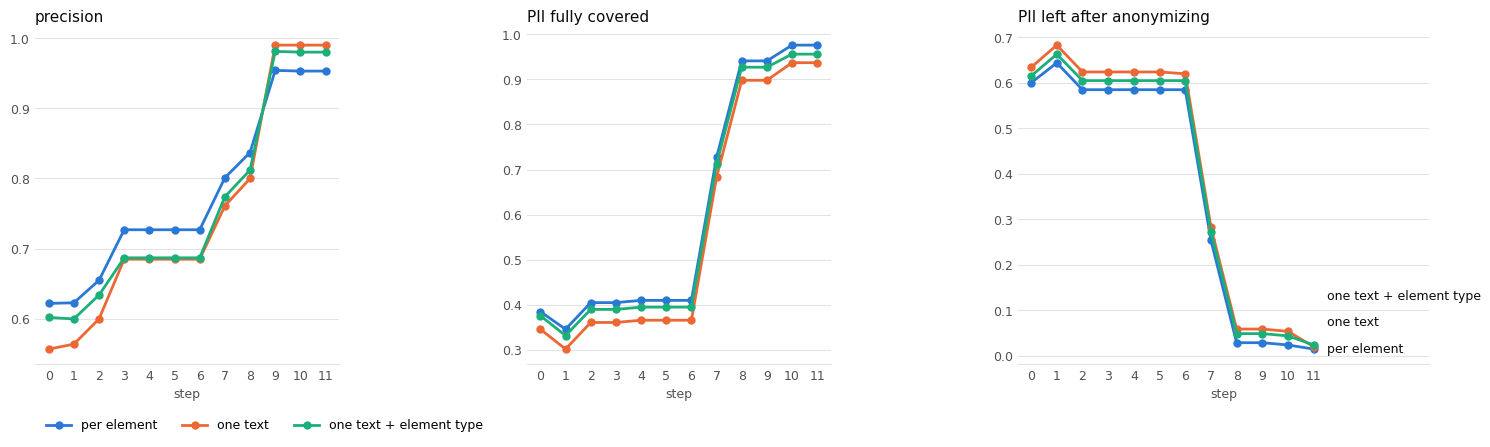

In [8]:
# Categorical slots 1-3 of the reference palette, one per mode; values are also in the tables above
COLORS = dict(zip(MODES, ["#2a78d6", "#eb6834", "#1baf7a"]))
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
PANELS = ["precision", "recall_full", "residual_pii"]

x = range(len(STEPS))
short = [name.split(" ", 1)[0] for name in STEPS]
# each panel has its own y-range (the differences are a few points); the last one is wider for the labels
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.35]})
for ax, metric in zip(axes, PANELS):
    for mode, color in COLORS.items():
        ax.plot(x, table[metric][mode], color=color, linewidth=2, marker="o", markersize=5, label=mode)
    ax.set_title(METRICS[metric], loc="left", fontsize=11, color=INK)
    ax.set_xticks(list(x), short)
    ax.set_xlabel("step", color=MUTED, fontsize=9)
    ax.tick_params(colors=MUTED, labelsize=9, length=0)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)

# direct labels at the line ends of the last panel, nudged apart when the values are close
ax, metric = axes[-1], PANELS[-1]
low, high = ax.get_ylim()
label_y, prev = {}, low - 1
for mode in sorted(MODES, key=lambda m: table[metric][m].iloc[-1]):
    prev = label_y[mode] = max(table[metric][mode].iloc[-1], prev + 0.08 * (high - low))
for mode in MODES:
    ax.annotate(mode, (len(STEPS) - 1, table[metric][mode].iloc[-1]), xytext=(len(STEPS) - 0.5, label_y[mode]),
                textcoords="data", va="center", fontsize=9, color=INK)
ax.set_xlim(-0.5, len(STEPS) + 3.5)
axes[0].legend(loc="upper left", frameon=False, fontsize=9, ncol=3, bbox_to_anchor=(0, -0.13))
fig.tight_layout()
plt.show()

Why is one text *less* precise up to step 8 and *more* precise from step 9? The false positives per entity type:

In [9]:
fp_by_type = pd.DataFrame({
    (name, mode): runs[mode, name].detections.loc[lambda d: ~d.tp].entity.value_counts()
    for name in ["8 Belgian recognizers", "11 name parts"]
    for mode in MODES
}).fillna(0).astype(int)
fp_by_type

8 Belgian recognizers                                  11 name parts  \
                   per element one text one text + element type   per element   
entity                                                                          
LOCATION                    30       48                      43             0   
PERSON                      10        2                       4            10   

                                           
         one text one text + element type  
entity                                     
LOCATION        0                       0  
PERSON          2                       4

In [10]:
d = runs["one text", "8 Belgian recognizers"].detections
d.loc[~d.tp & (d.entity == "LOCATION")].match.value_counts().head(12)

match
Mercurius          4
Plaatsbezoek       3
Aanvragen          3
Testdossier        3
Huwelijksboekje    3
Turnhout           2
Poperinge          2
Risicovol          2
Gedomicilieerd     2
Sint-Niklaas       2
Aalter             2
Hasselt            2
Name: count, dtype: int64

In one text, LOCATION fires more often (48 instead of 30 false positives at step 8): a capitalized word at the start
of its own line ("Aanvragen.", "Testdossier", "Mercurius") is taken for a place. PERSON, on the other hand, fires
much less often on capitalized nouns, because they now appear in sentences. Once LOCATION is dropped (step 9), only
the PERSON advantage remains.

## What one text per diagram changes at step 11

In [11]:
last = list(STEPS)[-1]
per_element = runs["per element", last]
for mode in ["one text", "one text + element type"]:
    r = runs[mode, last]
    d = pii_eval.diff_steps((per_element.spans, per_element.detections), (r.spans, r.detections))
    print(f"=== {mode} vs per element: {r.row['crossing_boundary']} detection(s) crossing an element boundary")
    for title in ["fp_removed", "fp_added", "pii_lost", "pii_gained"]:
        print(f"\n--- {title}: {len(d[title])}")
        if len(d[title]):
            display(d[title])

=== one text vs per element: 0 detection(s) crossing an element boundary

--- fp_removed: 8


,location,entity,match
1,name,PERSON,Plaatsbezoek
2,documentation,PERSON,Opgelet
3,name,PERSON,Plaatsbezoek
4,name,PERSON,Mobiliteitsambtenaar
5,name,PERSON,OMV_2022098043
7,name,PERSON,Adviezen
8,name,PERSON,Adviezen
9,documentation,PERSON,Opgelet



--- fp_added: 0

--- pii_lost: 8


,file,location,entity,value,text
3,aanvraag-rijbewijs-sintniklaas.bpmn,name,PERSON,Marleen,Marleen - Burgerzaken
6,aanvraag-rijbewijs-sintniklaas.bpmn,name,PERSON,Marleen Van de Velde,Dossier Marleen Van de Velde (°6 juni 1998)
25,omgevingsvergunning-poperinge.bpmn,name,PERSON,Fien,Fien - Burgerzaken
55,subsidie-vereniging-aalst.bpmn,name,PERSON,Marleen Jacobs,Dossier Marleen Jacobs (°04/03/1996)
76,melding-openbaar-domein-roeselare.bpmn,name,PERSON,Marleen,Marleen - Burgerzaken
93,aanvraag-rijbewijs-tienen.bpmn,name,PERSON,Marleen,Contact Marleen (+32493276528)
162,subsidie-vereniging-aalter.bpmn,name,PERSON,Mohamed,Mohamed - Burgerzaken
191,melding-openbaar-domein-hasselt.bpmn,name,PERSON,Tom,Tom - Burgerzaken



--- pii_gained: 1


...

,location,entity,match
1,name,PERSON,Evenementenloket



--- pii_lost: 4


,file,location,entity,value,text
24,omgevingsvergunning-poperinge.bpmn,name,PERSON,Elke Desmet,Elke Desmet
55,subsidie-vereniging-aalst.bpmn,name,PERSON,Marleen Jacobs,Dossier Marleen Jacobs (°04/03/1996)
93,aanvraag-rijbewijs-tienen.bpmn,name,PERSON,Marleen,Contact Marleen (+32493276528)
191,melding-openbaar-domein-hasselt.bpmn,name,PERSON,Tom,Tom - Burgerzaken



--- pii_gained: 1


,file,location,entity,value,text
141,huwelijk-genk.bpmn,name,PERSON,Lander Yilmaz,Doorsturen naar Lander Yilmaz


Per location and per entity (PII fully covered and PII left after anonymizing):

In [12]:
long = pd.concat(
    [r.summary.assign(mode=mode) for (mode, name), r in runs.items() if name == last]
)

def by_mode(group, metric):
    return long.loc[long.group == group].pivot(index="scope", columns="mode", values=metric)[list(MODES)]

pd.concat({"recall_full": by_mode("location", "recall_full"), "residual_pii": by_mode("location", "residual_pii")}, axis=1)

recall_full                                  residual_pii  \
mode          per element one text one text + element type  per element   
scope                                                                     
documentation       0.968    0.968                   0.968        0.032   
name                0.972    0.899                   0.936        0.009   
text                1.000    1.000                   1.000        0.000   

                                                
mode          one text one text + element type  
scope                                           
documentation    0.032                   0.032  
name             0.018                   0.028  
text             0.000                   0.000

In [13]:
pd.concat({"recall_full": by_mode("entity", "recall_full"), "residual_pii": by_mode("entity", "residual_pii")}, axis=1)

recall_full                                  residual_pii  \
mode          per element one text one text + element type  per element   
scope                                                                     
ADDRESS             1.000    1.000                   1.000        0.000   
DATE_OF_BIRTH       1.000    1.000                   1.000        0.000   
EMAIL               1.000    1.000                   1.000        0.000   
IBAN                1.000    1.000                   1.000        0.000   
KBO                 1.000    1.000                   1.000        0.000   
LICENSE_PLATE       1.000    1.000                   1.000        0.000   
PERSON              0.947    0.863                   0.905        0.032   
PHONE               1.000    1.000                   1.000        0.000   
RRN                 1.000    1.000                   1.000        0.000   

                                                
mode          one text one text + element type  
scope                                           
ADDRESS          0.000                   0.000  
DATE_OF_BIRTH    0.000                   0.000  
EMAIL            0.000                   0.000  
IBAN             0.000                   0.000  
KBO              0.000                   0.000  
LICENSE_PLATE    0.000                   0.000  
PERSON           0.042                   0.053  
PHONE            0.000                   0.000  
RRN              0.000                   0.000

In [14]:
out = pd.concat([r.summary.assign(mode=mode) for (mode, name), r in runs.items()])
out = out[["mode", *experiment.SUMMARY_COLUMNS]]
Path("results").mkdir(exist_ok=True)
out.to_csv("results/one_text.csv", index=False)
print(f"{len(out)} rows -> results/one_text.csv")

468 rows -> results/one_text.csv


## Conclusions

**Cost:** one text per diagram needs **20 analyzer calls instead of 551** (one per diagram), and detection is about
3–4× faster (≈0.45 s instead of ≈1.9 s for all 20 diagrams). No detection crossed an element boundary, so mapping
back to the elements is safe.

**Precision depends on LOCATION.** Up to step 8 one text is 2–6 points *less* precise, because LOCATION fires on
capitalized words at the start of a line. Once LOCATION is dropped (step 9), one text is *more* precise: 0.99
(plain) and 0.98 (with element type) against 0.95 per element, and the review list at step 11 has 2 and 4 items that
are not PII instead of 9. Sentences around "Adviezen", "Opgelet" and "Plaatsbezoek" stop them being taken for names.

**Recall is a little lower in every step.** At step 11, PII fully covered is 0.937 (plain) and 0.956 (with element
type) against 0.976 per element. The names lost are almost all first names or names in very short labels
("Tom - Burgerzaken", "Contact Marleen (…)", "Dossier Marleen Jacobs (°…)"). Masking name parts (step 11) recovers
some of them when the person is found elsewhere: PII left after anonymizing is 2.0% (plain) and 2.4% (with element
type) against 1.5% per element.

**Layout:** prefixing each line with the element type recovers about 2 points of recall compared to plain lines, at the
cost of 2 more false positives. Neither layout is better on all counts.

**Per element vs. one text, in short:** per element finds the most PII; one text is cheaper, gives a shorter and
cleaner review list, and is the natural input for a single-pass detection endpoint, at the price of a few names in
short labels.

**Next steps for one text per diagram**
1. **Hybrid:** one text per diagram, plus a per-element pass only for short labels (pools, lanes and tasks of a few
   words), where the lost names are. This keeps most of the cost gain.
2. **First names:** a recognizer with common first names in Belgium would catch "Tom - Burgerzaken" in either mode.
3. **Real data:** both modes should be compared on real OPH diagrams; the synthetic corpus has many very short labels.